In [ ]:
import copy
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader

from ddpm.data.das_dataset import DasDataset
from ddpm.diffusion.rad_noise_scheduler import RADNoiseScheduler
from ddpm.models.unet_rad import RAD
from ddpm.masks.rad_masks import random_rad_mask, channel_strip
from ddpm.diffusion.rad_inpainting import rad_inpaint
from ddpm.training.rad_training3 import train_rad
from ddpm.plotting.loss_plot import update_loss_plot

device="cuda" if torch.cuda.is_available() else "cpu"

das_data=Path("/datasets/training/earthquake/share/SISSLE_south30")
train_loader_earthquake=DataLoader(DasDataset([das_data/"train_1001.h5"]),batch_size=16,shuffle=True)
test_loader_earthquake=DataLoader(DasDataset([das_data/"test_1001.h5"]),batch_size=16,shuffle=False)

scheduler_rad=RADNoiseScheduler(ph1_steps=1000,ph2_steps=1000,beta_start=1e-4,beta_end=0.02,device=device)

checkpoints=Path("checkpoints")
with open(checkpoints/"data_scaling.json") as f: scaling=json.load(f)
data_scale=scaling["data_scale"]      # 2.023
clip_value=scaling["clip_value"]      # 2.397 
print("data_scale:",data_scale,"| clip_value:",clip_value)

checkpoint_meta={
    "base_channels":64,"channels_multiplier":(1,1,2,2,4),
    "normalization":{"function":"arcsinh","s":50.0,"A_max":12350.0},
    "data_scaling":scaling,
    "model_key":"model_rad","optimizer_key":"optimizer_rad","train_loss_key":"train_losses","val_loss_key":"val_losses"
}

data_scale: 2.023162409488313 | clip_value: 2.397387999610823


In [2]:
model_rad=RAD(in_channels=1,out_channels=1,base_channels=64,channels_multiplier=(1,1,2,2,4),nbr_rb=2,dropout=0.1).to(device)
optimizer_rad=torch.optim.Adam(model_rad.parameters(),lr=1e-4)

model_path_v2=checkpoints/"das_rad_earthquake_model_v2.pth"
model_path_v3=checkpoints/"das_rad_earthquake_model_v3.pth"
loss_plot_path_v3=checkpoints/"das_rad_earthquake_loss_v3.png"

if model_path_v3.exists():
    ckpt=torch.load(model_path_v3,map_location=device)
    model_rad.load_state_dict(ckpt["model_rad"])
    optimizer_rad.load_state_dict(ckpt["optimizer_rad"])
    ema_rad=copy.deepcopy(model_rad); ema_rad.load_state_dict(ckpt["ema_model_rad"])
    train_losses=ckpt.get("train_losses",[]); val_losses=ckpt.get("val_losses",[])
    start_epoch=ckpt["completed_epochs"]
    print("resuming v3 from epoch",start_epoch)
else:
    ema_rad=copy.deepcopy(model_rad)     
    train_losses=[]; val_losses=[]
    start_epoch=0
    print("training v3 from scratch")

training v3 from scratch


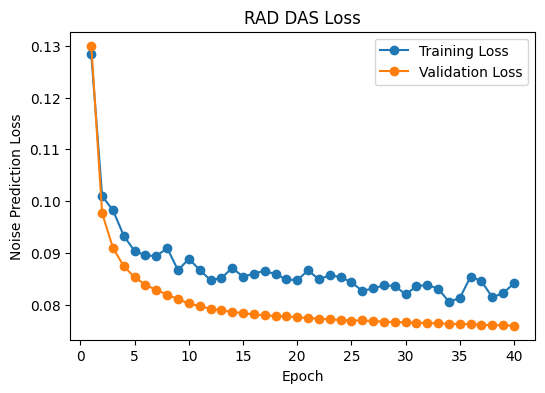

In [3]:
epochs=40   

train_losses,val_losses,ema_rad=train_rad(
    model=model_rad,
    train_loader=train_loader_earthquake,
    val_loader=test_loader_earthquake,
    scheduler=scheduler_rad,
    optimizer=optimizer_rad,
    device=device,
    epochs=epochs,
    checkpoint_path=model_path_v3,
    model_key="model_rad",
    optimizer_key="optimizer_rad",
    train_loss_key="train_losses",
    val_loss_key="val_losses",
    start_epoch=start_epoch,
    train_losses=train_losses,
    val_losses=val_losses,
    checkpoint_meta=checkpoint_meta,
    plot_function=update_loss_plot,
    loss_plot_path=loss_plot_path_v3,
    ema_model=ema_rad,
    ema_decay=0.999,
    phase1_prob=0.75,
    masked_loss=True,
    data_scale=data_scale
)

In [4]:
from ddpm.diffusion.rad_inpainting_scaled import inpaint_scaled
from ddpm.evaluation.spectral_metrics import collect_hole_rows, psd, band_ratios

In [5]:
from ddpm.diffusion.rddim2 import generate_rddim_samples as generate_rddim_samples2
from ddpm.utils.normalizer import denormalize

# v3 generates in scaled space: clip at clip_value (2.397), then divide by data_scale
samples_v3_scaled=generate_rddim_samples2(model=ema_rad,scheduler=scheduler_rad,num_samples=1024,batch_size=16,
                                          num_steps=100,device=device,eta=0.0,seed=42,clip_x0=clip_value)
samples_v3=samples_v3_scaled/data_scale
torch.save(samples_v3,checkpoints/"rad_v3_rddim_1024_clip.pt")

# v1 (clipped) samples from train_rad.ipynb, and real test data
samples_v1=torch.load(checkpoints/"rad_rddim_1024_clip.pt")
real_samples=torch.cat([b for b in test_loader_earthquake],dim=0)[:1024]

real_d=denormalize(real_samples).detach().cpu().numpy().astype(np.float64)
v1_d=denormalize(samples_v1).detach().cpu().numpy().astype(np.float64)
v3_d=denormalize(samples_v3).detach().cpu().numpy().astype(np.float64)

print("percentile | real | v1 clip | v3 scaled")
for p in [50,60,90,99,99.9,99.99]:
    print(f"{p}% | {np.percentile(np.abs(real_d),p):.2f} | {np.percentile(np.abs(v1_d),p):.2f} | {np.percentile(np.abs(v3_d),p):.2f}")

rms=lambda a: np.sqrt(np.mean(a**2,axis=(1,2,3)))
print("RMS median | real:",round(np.median(rms(real_d)),2),"| v1:",round(np.median(rms(v1_d)),2),"| v3:",round(np.median(rms(v3_d)),2))
print("max abs    | real:",round(np.max(np.abs(real_d)),2),"| v1:",round(np.max(np.abs(v1_d)),2),"| v3:",round(np.max(np.abs(v3_d)),2))

RDDIM Samples: 100%|██████████| 64/64 [15:48<00:00, 14.82s/it, generated=1024]


percentile | real | v1 clip | v3 scaled
50% | 41.86 | 107.48 | 36.79
60% | 55.94 | 142.40 | 46.78
90% | 248.72 | 411.63 | 107.36
99% | 1229.64 | 1252.33 | 263.74
99.9% | 2891.07 | 3082.34 | 659.57
99.99% | 5326.53 | 7219.19 | 1706.01
RMS median | real: 79.12 | v1: 293.44 | v3: 68.68
max abs    | real: 19360.99 | v1: 22963.66 | v3: 38898.16


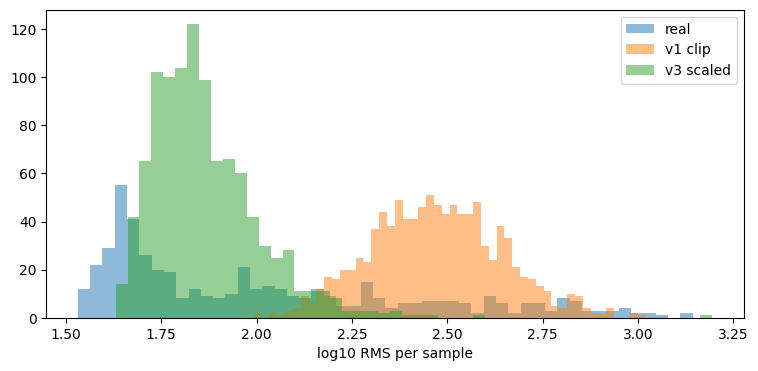

In [6]:
plt.figure(figsize=(9,4))
plt.hist(np.log10(rms(real_d)),bins=50,alpha=0.5,label="real")
plt.hist(np.log10(rms(v1_d)),bins=50,alpha=0.5,label="v1 clip")
plt.hist(np.log10(rms(v3_d)),bins=50,alpha=0.5,label="v3 scaled")
plt.xlabel("log10 RMS per sample"); plt.legend(); plt.show()

In [8]:
model_path_old=checkpoints/"das_rad_earthquake_model.pth"

model_v1=copy.deepcopy(ema_rad)
model_v1.load_state_dict(torch.load(model_path_old,map_location=device)["model_rad"])   # v1 has no EMA
model_v1.eval()

model_v2=copy.deepcopy(ema_rad)
model_v2.load_state_dict(torch.load(model_path_v2,map_location=device)["ema_model_rad"])
model_v2.eval()

RAD(
  (spatial_noise_embedding): SpatialNoiseEmbedding(
    (sinusoidal_emb): SpatialSinusoidalEmb()
  )
  (in_conv): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down_levels): ModuleList(
    (0-1): 2 x DownLevel(
      (blocks): ModuleList(
        (0-1): 2 x ResBlock(
          (block1): Block(
            (layers): Sequential(
              (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
              (1): RMSNorm(
                (norm): RMSNorm((64,), eps=None, elementwise_affine=True)
              )
              (2): SiLU()
              (3): Dropout(p=0.1, inplace=False)
            )
          )
          (block2): Block(
            (layers): Sequential(
              (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
              (1): RMSNorm(
                (norm): RMSNorm((64,), eps=None, elementwise_affine=True)
              )
              (2): SiLU()
              (3): Dropout(p=0.0, inplace=False)


In [9]:
'''inference using only phase 1: v1 vs v2 vs v3'''
x0=next(iter(test_loader_earthquake))[:2].to(device)
B,C,H,W=x0.shape

g=torch.Generator(device=device).manual_seed(1)
mask=random_rad_mask(B,H,W,device,generator=g)

shown=[999,750,500,250,100,0]

res_v1,_,steps_v1=inpaint_scaled(model_v1,scheduler_rad,x0,mask,device,scale=1.0,
                                 generator=torch.Generator(device=device).manual_seed(0),timesteps_shown=shown)
res_v2,_,steps_v2=inpaint_scaled(model_v2,scheduler_rad,x0,mask,device,scale=1.0,
                                 generator=torch.Generator(device=device).manual_seed(0),timesteps_shown=shown)
res_v3,_,steps_v3=inpaint_scaled(ema_rad,scheduler_rad,x0,mask,device,scale=data_scale,
                                 generator=torch.Generator(device=device).manual_seed(0),timesteps_shown=shown)

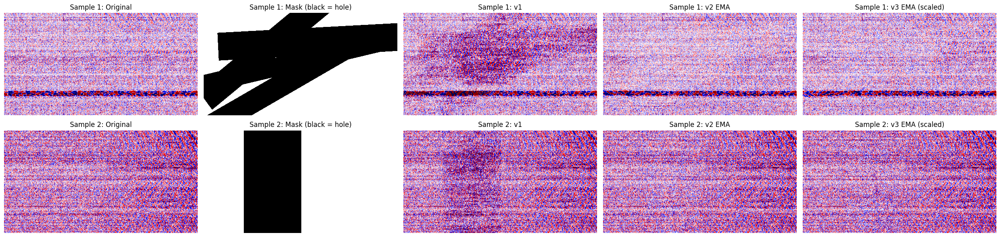

In [10]:
w=0.5
fig,axes=plt.subplots(2,5,figsize=(25,6))
for i in range(2):
    panels=[(x0[i,0],"Original"),(mask[i,0],"Mask (black = hole)"),
            (res_v1[i,0],"v1"),(res_v2[i,0],"v2 EMA"),(res_v3[i,0],"v3 EMA (scaled)")]
    for j,(img,title) in enumerate(panels):
        img=img.detach().cpu()
        if j==1: axes[i,j].imshow(img,aspect="auto",cmap="gray")
        else:    axes[i,j].imshow(img,aspect="auto",cmap="seismic",vmin=-w,vmax=w)
        axes[i,j].set_title(f"Sample {i+1}: {title}"); axes[i,j].axis("off")
plt.tight_layout()
plt.show()

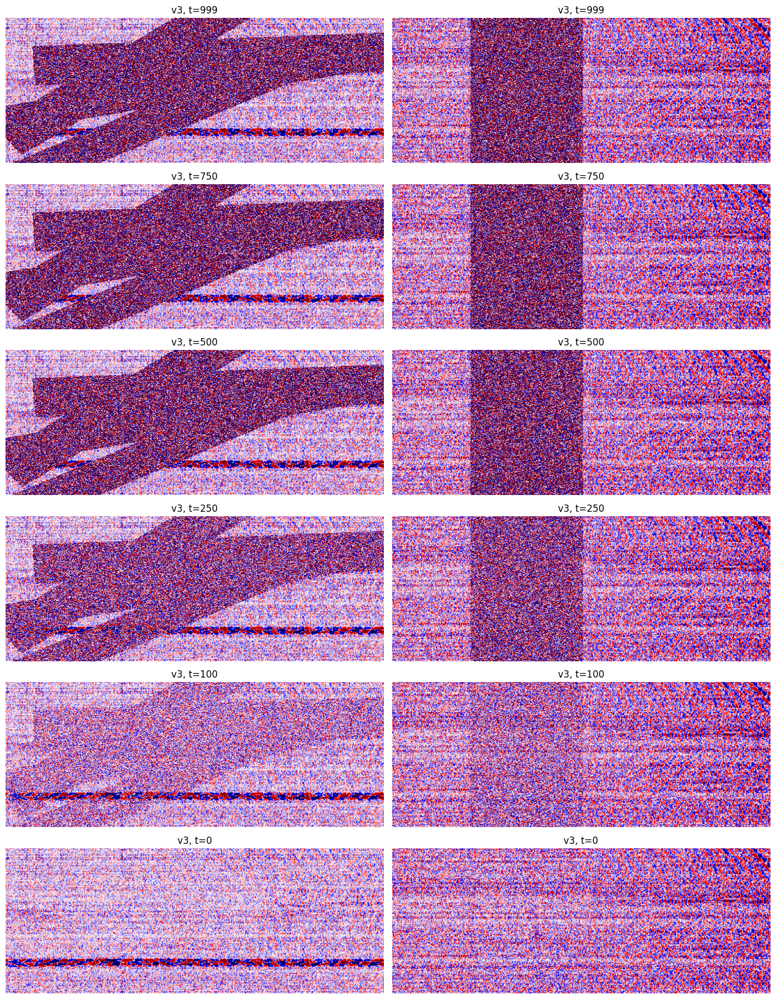

In [11]:
steps=list(steps_v3.keys())
fig,axes=plt.subplots(len(steps),2,figsize=(14,3*len(steps)))
for row,step in enumerate(steps):
    for i in range(2):
        sample=steps_v3[step][i,0].detach().cpu()
        axes[row,i].imshow(sample,aspect="auto",cmap="seismic",vmin=-w,vmax=w)
        axes[row,i].axis("off")
        axes[row,i].set_title(f"v3, t={step}")
plt.tight_layout()
plt.show()

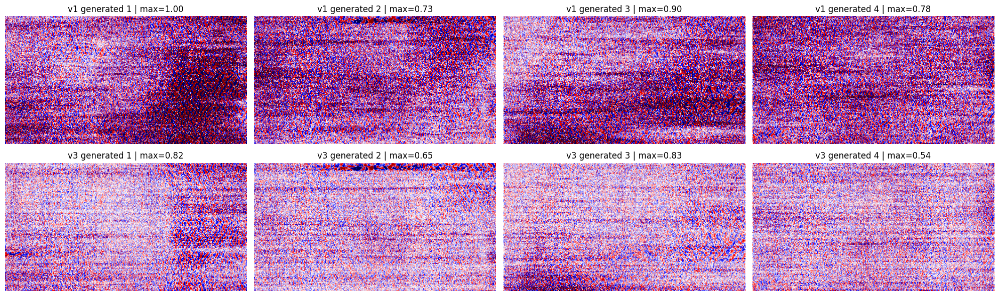

In [12]:
samples_v1=torch.load(checkpoints/"rad_rddim_1024_clip.pt")
samples_v3=torch.load(checkpoints/"rad_v3_rddim_1024_clip.pt")
gen=[("v1",samples_v1),("v3",samples_v3)]
if (checkpoints/"rad_v2_rddim_1024_clip.pt").exists():
    gen.insert(1,("v2",torch.load(checkpoints/"rad_v2_rddim_1024_clip.pt")))

fig,axes=plt.subplots(len(gen),4,figsize=(20,3*len(gen)))
for r,(name,s) in enumerate(gen):
    for i in range(4):
        axes[r,i].imshow(s[i,0].cpu(),aspect="auto",cmap="seismic",vmin=-w,vmax=w)
        axes[r,i].set_title(f"{name} generated {i+1} | max={s[i].abs().max():.2f}"); axes[r,i].axis("off")
plt.tight_layout()
plt.show()

In [13]:
from ddpm.masks.rad_masks import time_strip

all_test=torch.cat([b for b in test_loader_earthquake],dim=0)
rms_test=all_test.pow(2).mean(dim=(1,2,3)).sqrt()
idx=torch.argsort(rms_test,descending=True)[:2]          # two loudest test windows
x0=all_test[idx].to(device)
print("chosen windows:",idx.tolist(),"| RMS:",rms_test[idx].tolist())

g=torch.Generator(device=device).manual_seed(3)
mask=time_strip(2,256,512,device,width_range=(0.15,0.25),count_range=(1,1),generator=g)

res_v1,_,_=inpaint_scaled(model_v1,scheduler_rad,x0,mask,device,scale=1.0,generator=torch.Generator(device=device).manual_seed(0))
res_v2,_,_=inpaint_scaled(model_v2,scheduler_rad,x0,mask,device,scale=1.0,generator=torch.Generator(device=device).manual_seed(0))
res_v3,_,_=inpaint_scaled(ema_rad,scheduler_rad,x0,mask,device,scale=data_scale,generator=torch.Generator(device=device).manual_seed(0))

chosen windows: [429, 384] | RMS: [0.5218995809555054, 0.5168628096580505]


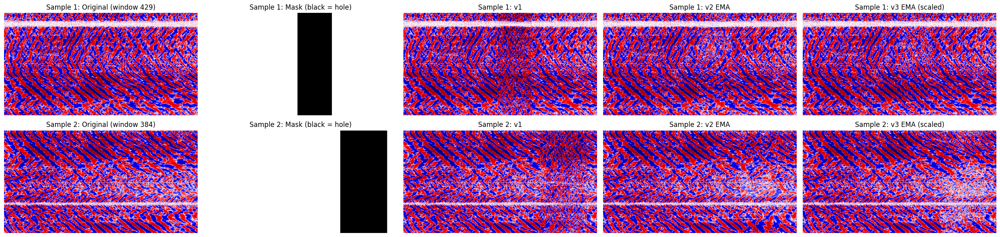

In [14]:
w=1.0
fig,axes=plt.subplots(2,5,figsize=(25,6))
for i in range(2):
    panels=[(x0[i,0],f"Original (window {idx[i].item()})"),(mask[i,0],"Mask (black = hole)"),
            (res_v1[i,0],"v1"),(res_v2[i,0],"v2 EMA"),(res_v3[i,0],"v3 EMA (scaled)")]
    for j,(img,title) in enumerate(panels):
        img=img.detach().cpu()
        if j==1: axes[i,j].imshow(img,aspect="auto",cmap="gray")
        else:    axes[i,j].imshow(img,aspect="auto",cmap="seismic",vmin=-w,vmax=w)
        axes[i,j].set_title(f"Sample {i+1}: {title}"); axes[i,j].axis("off")
plt.tight_layout()
plt.show()

In [16]:
def hole_stats(res,x0,mask,edge=10):
    out=[]
    for i in range(x0.shape[0]):
        cols=(mask[i,0,0,:]==0).nonzero().flatten()
        a,b=cols.min().item(),cols.max().item()+1
        t=x0[i,0,:,a:b].cpu(); g=res[i,0,:,a:b].cpu()
        rms=(g.pow(2).mean().sqrt()/t.pow(2).mean().sqrt()).item()
        zc=lambda s: (torch.sign(s[:,1:])!=torch.sign(s[:,:-1])).float().mean()
        zcr=(zc(g)/zc(t)).item()
        corr=lambda u,v: torch.corrcoef(torch.stack([u.flatten(),v.flatten()]))[0,1].item()
        edge_corr=(corr(t[:,:edge],g[:,:edge])+corr(t[:,-edge:],g[:,-edge:]))/2
        out.append((round(rms,2),round(zcr,2),round(edge_corr,2),round(corr(t,g),2)))
    return out

print("per sample: (RMS ratio, zero-crossing ratio, correlation at hole edges, correlation whole hole)")
for name,res in [("v1",res_v1),("v2",res_v2),("v3",res_v3)]:
    print(name,hole_stats(res,x0,mask))

per sample: (RMS ratio, zero-crossing ratio, correlation at hole edges, correlation whole hole)
v1 [(1.12, 1.45, 0.19, 0.05), (1.09, 1.92, 0.14, 0.03)]
v2 [(0.91, 1.14, 0.43, 0.1), (0.95, 1.23, 0.44, 0.12)]
v3 [(0.97, 1.21, 0.42, 0.06), (0.87, 1.39, 0.42, 0.08)]


In [17]:
idx32=torch.argsort(rms_test,descending=True)[:32]
X=all_test[idx32]
g=torch.Generator(device=device).manual_seed(3)
M=time_strip(32,256,512,device,width_range=(0.15,0.25),count_range=(1,1),generator=g)

results={}
for name,model,scale in [("v1",model_v1,1.0),("v2",model_v2,1.0),("v3",ema_rad,data_scale)]:
    stats=[]
    for s in range(0,32,16):
        x=X[s:s+16].to(device); m=M[s:s+16]
        r,_,_=inpaint_scaled(model,scheduler_rad,x,m,device,scale=scale,generator=torch.Generator(device=device).manual_seed(0))
        stats+=hole_stats(r,x,m)
    stats=np.array(stats)
    results[name]=stats
    print(f"{name} | RMS {stats[:,0].mean():.2f}±{stats[:,0].std():.2f} | ZCR {stats[:,1].mean():.2f}±{stats[:,1].std():.2f} | edge corr {stats[:,2].mean():.2f}±{stats[:,2].std():.2f}")

v1 | RMS 1.10±0.06 | ZCR 1.30±0.16 | edge corr 0.15±0.06
v2 | RMS 0.90±0.04 | ZCR 1.11±0.09 | edge corr 0.28±0.06
v3 | RMS 0.93±0.05 | ZCR 1.13±0.08 | edge corr 0.28±0.08
